# 02 — Variables, binning WOE e IV

**Objetivo.** Construir las variables candidatas, agruparlas en bins con weight of evidence (WOE),
medir cuánta información aporta cada una (IV) y decidir cuáles pasan al modelo de la fase
siguiente. Las decisiones quedan registradas en `docs/DECISIONS.md` (ADR-009 y ADR-011).

**Todo se calcula solo con la parte de entrenamiento** (24,000 filas). El conjunto de test no se
carga en este notebook.

Convenciones:

- WOE de un bin = ln(proporción de no-defaults del bin / proporción de defaults del bin). Un bin
  más riesgoso que el promedio tiene WOE negativo.
- IV = suma, sobre los bins, de (proporción de no-defaults − proporción de defaults) × WOE.
- Bandas habituales del IV: <0.02 inútil, 0.02–0.1 débil, 0.1–0.3 medio, 0.3–0.5 fuerte,
  >0.5 sospechoso (revisar fuga de información).

Todos los cálculos están en `creditrisk.features`. Este notebook llama a `woe_iv_report`, que
produce todas las cifras de una sola vez, y las guarda en `reports/metrics/woe_iv.json`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from creditrisk import plotting
from creditrisk.config import load_config
from creditrisk.data.schema import MONTH_LABELS
from creditrisk.data.split import load_train
from creditrisk.features.engineering import FEATURE_SPECS, build_features
from creditrisk.features.selection import EXCLUDED_FROM_CHAMPION, woe_iv_report
from creditrisk.reporting import save_metrics

plotting.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

BANDS = {
    "useless": "inútil",
    "weak": "débil",
    "medium": "medio",
    "strong": "fuerte",
    "suspicious": "sospechoso",
}
TRENDS = {"ascending": "sube", "descending": "baja", None: "sin restricción"}

## 1. Datos de entrenamiento y variables candidatas

Las variables se construyen fila por fila a partir de las columnas de cada cliente, sin ajustar
nada a los datos (`build_features`). Cada una responde a una idea de negocio:

| Grupo | Variables | Idea |
|---|---|---|
| Límite | `LIMIT_BAL` | El banco da límites más altos a clientes en quienes ya confía. |
| Demográficas | `AGE`, `EDUCATION` | Candidatas solo con justificación (ADR-002). |
| Utilización | `UTIL_1`…`UTIL_6`, `UTIL_MEAN`, `UTIL_MAX`, `UTIL_TREND` | Factura / límite. Una línea más usada indica más tensión financiera. La factura negativa cuenta como cero. |
| Ratio de pago | `PAY_RATIO_1`…`PAY_RATIO_5`, `PAY_RATIO_MEAN` | Pago del mes / estado de cuenta que cancela (ADR-009). Sin nada que pagar, el valor queda vacío y va a un bin propio. |
| Historial de mora | `N_DELAY_MONTHS`, `MAX_DELAY`, `MONTHS_SINCE_DELAY` | Atrasos de agosto a abril, los meses con codificación consistente (ADR-008). |
| Estado de pago | `STATUS_SEP`, `STATUS_AUG` | Estado de septiembre y de agosto como categorías; los atrasos de 3 o más meses se agrupan en "3+". |
| Inactividad | `INACTIVE` | Todas las facturas y pagos en cero. |

In [2]:
train = load_train()
features = build_features(train)
print(f"Filas de entrenamiento: {len(train):,}")
print(f"Variables candidatas:   {features.shape[1]}")

# The whole Phase 4 analysis: binning, IV, stability across folds and preselection.
report = woe_iv_report(train)

Filas de entrenamiento: 24,000
Variables candidatas:   24


## 2. Reglas del binning

Cada bin debe tener al menos el 5% de las filas. Para las variables numéricas se declaró, antes de
mirar los datos y según la lógica de negocio, en qué dirección debe moverse la tasa de default; el
binning respeta esa dirección. Los valores vacíos van a un bin propio.

In [3]:
settings = report["settings"]
rules = pd.DataFrame(
    {
        "tipo": {k: v["dtype"] for k, v in FEATURE_SPECS.items()},
        "la tasa de default ... al crecer la variable": {
            k: TRENDS[v] for k, v in settings["monotonic_trend"].items()
        },
    }
)
print(f"Tamaño mínimo de bin: {settings['min_bin_size']:.0%} de las filas")
display(rules)

Tamaño mínimo de bin: 5% de las filas


,tipo,la tasa de default ... al crecer la variable
LIMIT_BAL,numerical,baja
AGE,numerical,sin restricción
EDUCATION,categorical,sin restricción
UTIL_1,numerical,sube
UTIL_2,numerical,sube
UTIL_3,numerical,sube
UTIL_4,numerical,sube
UTIL_5,numerical,sube
UTIL_6,numerical,sube
UTIL_MEAN,numerical,sube


## 3. Information value de cada variable

La columna `IV (optbinning)` es el IV que calcula la librería que encuentra los cortes; la columna
`IV` es nuestro propio cálculo sobre los mismos bins. Deben coincidir: es la verificación cruzada
que pide la fase.

In [4]:
iv = pd.DataFrame(report["iv_table"]).set_index("feature").sort_values("iv", ascending=False)
iv_view = pd.DataFrame(
    {
        "IV": iv["iv"].round(3),
        "IV (optbinning)": iv["optbinning_iv"].round(3),
        "banda": iv["band"].map(BANDS),
        "bins": iv["n_bins"],
        "bin de vacíos": iv["has_missing_bin"].map({True: "sí", False: "no"}),
    }
)
iv_view.index.name = "variable"
display(iv_view)
print(
    f"Máxima diferencia entre los dos cálculos de IV: {(iv['iv'] - iv['optbinning_iv']).abs().max():.1e}"
)

,IV,IV (optbinning),banda,bins,bin de vacíos
variable,,,,,
STATUS_SEP,0.873,0.873,sospechoso,5,no
N_DELAY_MONTHS,0.641,0.641,sospechoso,4,no
MONTHS_SINCE_DELAY,0.630,0.630,sospechoso,2,sí
STATUS_AUG,0.550,0.550,sospechoso,4,no
MAX_DELAY,0.531,0.531,sospechoso,2,no
PAY_RATIO_1,0.266,0.266,medio,5,sí
PAY_RATIO_2,0.218,0.218,medio,6,sí
PAY_RATIO_MEAN,0.210,0.210,medio,7,sí
PAY_RATIO_3,0.193,0.193,medio,4,sí


Máxima diferencia entre los dos cálculos de IV: 1.1e-16


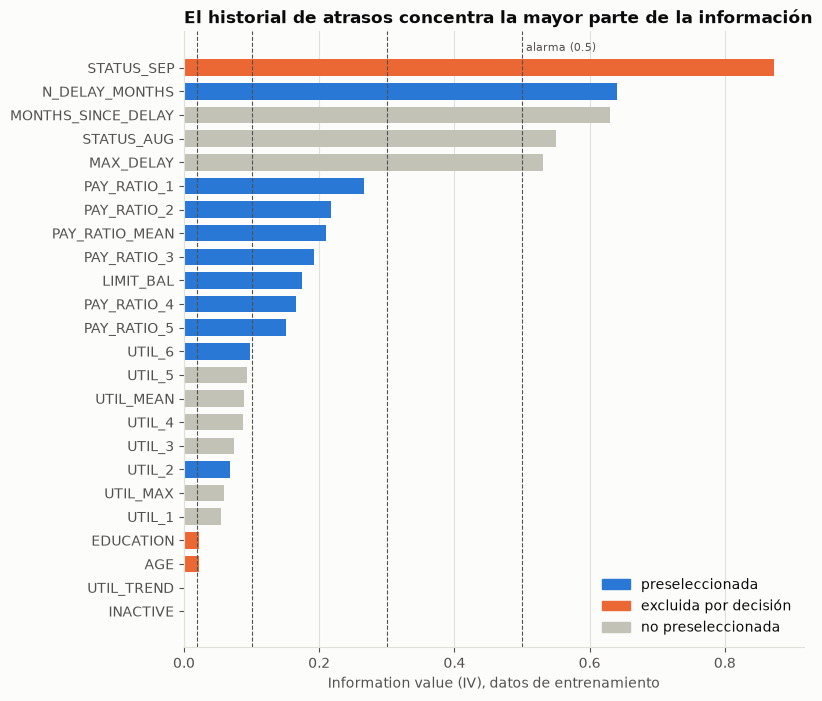

In [5]:
shortlist = set(report["shortlist"])
excluded = set(EXCLUDED_FROM_CHAMPION)
ordered = iv.sort_values("iv")


def group(name):
    if name in shortlist:
        return "preseleccionada"
    if name in excluded:
        return "excluida por decisión"
    return "no preseleccionada"


colours = {
    "preseleccionada": plotting.BLUE,
    "excluida por decisión": plotting.ORANGE,
    "no preseleccionada": "#c3c2b7",
}
fig, ax = plt.subplots(figsize=(8, 8))
groups = ordered.index.map(group)
ax.barh(ordered.index, ordered["iv"], color=[colours[g] for g in groups], height=0.7)
for threshold in (0.02, 0.1, 0.3, 0.5):
    ax.axvline(threshold, color=plotting.MUTED, linewidth=0.8, linestyle="--")
ax.text(0.5, len(ordered) - 0.4, " alarma (0.5)", color=plotting.MUTED, fontsize=8, va="bottom")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()]
ax.legend(handles, colours.keys(), loc="lower right")
ax.set_xlabel("Information value (IV), datos de entrenamiento")
ax.grid(axis="y", visible=False)
ax.set_title("El historial de atrasos concentra la mayor parte de la información")
plotting.save_figure(fig, "woe_iv_by_feature")
plt.show()

## 4. Variables por encima del umbral de alarma (IV > 0.5)

Cinco variables superan 0.5: el estado de septiembre, el estado de agosto y las tres variables de
historial de mora. Un IV tan alto puede indicar fuga de información, así que cada una se revisa.

### El estado de septiembre (`PAY_1`)

ADR-009 dejó pendiente esta verificación: no se puede demostrar que `PAY_1` se registró antes del
resultado de octubre. El gráfico muestra el IV del estado de pago de cada mes, con la misma regla de
agrupación.

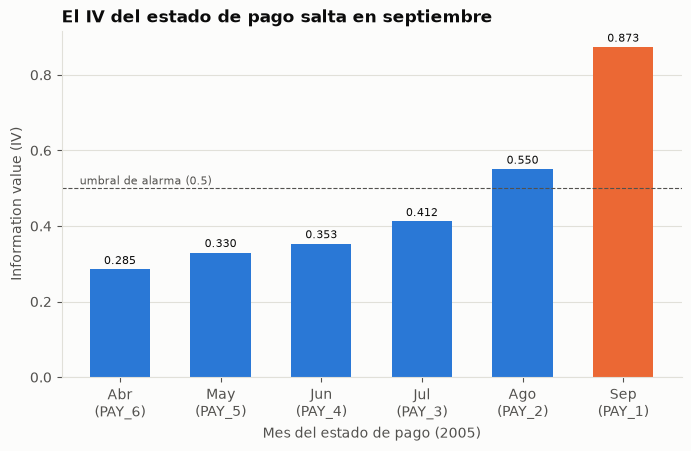

In [6]:
by_month = pd.Series(report["pay_1_check"]["status_iv_by_month"]).sort_index(ascending=False)
labels = [f"{MONTH_LABELS[int(k)]}\n(PAY_{k})" for k in by_month.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
colours = [plotting.ORANGE if int(k) == 1 else plotting.BLUE for k in by_month.index]
bars = ax.bar(labels, by_month.to_numpy(), color=colours, width=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in by_month], padding=2, fontsize=8)
ax.axhline(0.5, color=plotting.MUTED, linewidth=0.8, linestyle="--")
ax.text(-0.4, 0.51, "umbral de alarma (0.5)", color=plotting.MUTED, fontsize=8)
ax.set_xlabel("Mes del estado de pago (2005)")
ax.set_ylabel("Information value (IV)")
ax.grid(axis="x", visible=False)
ax.set_title("El IV del estado de pago salta en septiembre")
plotting.save_figure(fig, "woe_status_iv_by_month")
plt.show()

El IV crece con la cercanía al resultado, lo que es esperable, pero el salto de agosto (0.550) a
septiembre (0.873) es mucho mayor que los anteriores. Puede ser solo recencia o puede ser
información del mes del resultado; el archivo no permite distinguirlo. Además, el notebook 01
mostró que septiembre se registró con un criterio distinto al de los meses anteriores.

**Decisión (ADR-009, actualizado).** El modelo campeón se construye **sin** `STATUS_SEP`. El modelo
con `STATUS_SEP` se ajusta en la fase siguiente solo como sensibilidad, para mostrar cuánto
ganaría la predicción si el dato fuera legítimo. Los montos de septiembre (`BILL_AMT1`, `PAY_AMT1`)
sí se usan: su timing quedó verificado en el notebook 01.

### El historial de agosto a abril

`N_DELAY_MONTHS`, `MONTHS_SINCE_DELAY`, `MAX_DELAY` y `STATUS_AUG` vienen de meses anteriores a
septiembre y con codificación consistente, así que no pueden contener información de octubre. Que
el historial de atrasos sea el predictor más fuerte es lo esperable en un scorecard de
comportamiento. **Decisión (ADR-011):** se conservan como candidatas.

## 5. Cómo se ve el riesgo dentro de los bins

Tasa de default por bin para cuatro variables, en los datos de entrenamiento. La línea horizontal es
la tasa promedio.

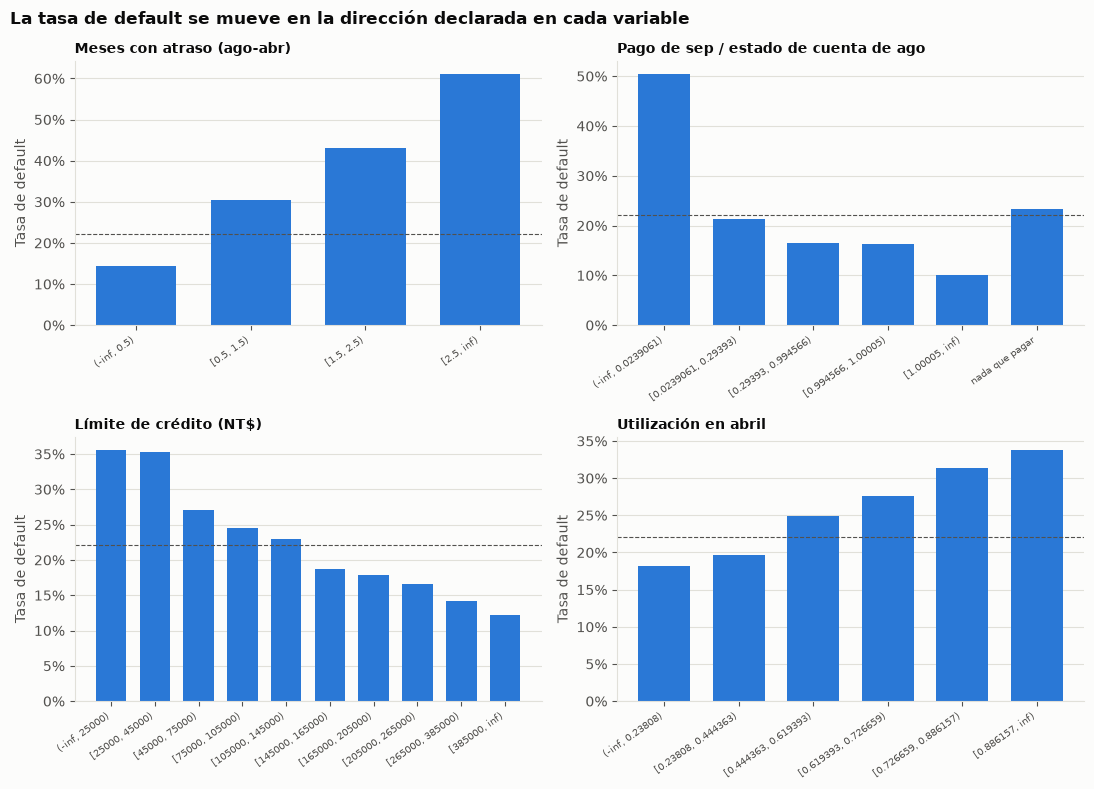

In [7]:
bins = report["bins"]
overall = train["DEFAULT"].mean()
panels = {
    "N_DELAY_MONTHS": "Meses con atraso (ago-abr)",
    "PAY_RATIO_1": "Pago de sep / estado de cuenta de ago",
    "LIMIT_BAL": "Límite de crédito (NT$)",
    "UTIL_6": "Utilización en abril",
}
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (name, title) in zip(axes.ravel(), panels.items(), strict=True):
    table = pd.DataFrame(bins[name])
    names = table["bin"].replace({"missing": "nada que pagar"})
    ax.bar(range(len(table)), table["event_rate"], color=plotting.BLUE, width=0.7)
    ax.axhline(overall, color=plotting.MUTED, linewidth=0.8, linestyle="--")
    ax.set_xticks(range(len(table)), names, rotation=35, ha="right", fontsize=7)
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_ylabel("Tasa de default")
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=10)
fig.suptitle(
    "La tasa de default se mueve en la dirección declarada en cada variable",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
plotting.save_figure(fig, "woe_event_rate_by_bin")
plt.show()

## 6. Estabilidad entre folds

El binning se vuelve a ajustar en cada uno de los 15 folds de validación cruzada (con 4/5 de
train) y se evalúa en el 1/5 que no vio:

- **IV fuera del fold**: el IV de esos mismos bins en las filas de validación. Con muestras chicas
  el IV tiende a inflarse, así que un IV de validación algo mayor que el de ajuste no es una buena
  noticia en sí.
- **Correlación de rangos del WOE**: si el orden de riesgo de los bins aprendido en el fold se
  mantiene en las filas que no vio (1 = se mantiene igual).

In [8]:
stability = pd.DataFrame(report["fold_stability"]).set_index("feature")
stability_view = pd.DataFrame(
    {
        "IV ajuste (media)": stability["iv_fit_mean"].round(3),
        "IV validación (media)": stability["iv_valid_mean"].round(3),
        "IV validación (mín)": stability["iv_valid_min"].round(3),
        "IV validación (máx)": stability["iv_valid_max"].round(3),
        "folds con IV ≥ 0.02": stability["n_folds_iv_valid_at_least_min"],
        "orden de riesgo (media)": stability["woe_rank_corr_mean"].round(2),
        "orden de riesgo (mín)": stability["woe_rank_corr_min"].round(2),
        "bins (mín-máx)": stability["n_bins_min"].astype(str)
        + "-"
        + stability["n_bins_max"].astype(str),
    }
)
stability_view.index.name = "variable"
display(stability_view.sort_values("IV ajuste (media)", ascending=False))

,IV ajuste (media),IV validación (media),IV validación (mín),IV validación (máx),folds con IV ≥ 0.02,orden de riesgo (media),orden de riesgo (mín),bins (mín-máx)
variable,,,,,,,,
STATUS_SEP,0.874,0.878,0.781,0.966,15,0.95,0.90,5-5
N_DELAY_MONTHS,0.642,0.640,0.560,0.730,15,1.00,1.00,4-4
MONTHS_SINCE_DELAY,0.630,0.631,0.551,0.680,15,1.00,1.00,2-2
STATUS_AUG,0.551,0.554,0.473,0.622,15,0.73,0.40,4-4
MAX_DELAY,0.531,0.531,0.468,0.588,15,1.00,1.00,2-2
PAY_RATIO_1,0.267,0.267,0.205,0.321,15,0.96,0.86,4-6
PAY_RATIO_2,0.219,0.216,0.170,0.257,15,0.95,0.83,5-6
PAY_RATIO_MEAN,0.212,0.210,0.161,0.246,15,0.96,0.87,7-8
PAY_RATIO_3,0.193,0.194,0.157,0.236,15,0.90,0.68,4-6


### `AGE` y `EDUCATION`

ADR-002 pide decidir aquí si estas variables entran al modelo, con su IV a la vista. Ambas tienen un
IV de entrenamiento apenas por encima de 0.02, y ninguna es estable:

- `AGE` llega a un IV de 0.02 fuera del fold en 13 de 15 folds, pero el orden de riesgo de sus bins
  no se sostiene (correlación de rangos media 0.66 y mínima 0.27).
- `EDUCATION` llega a un IV de 0.02 fuera del fold solo en 10 de 15 folds.

**Decisión (ADR-011).** Ninguna de las dos entra al modelo. Ambas se incluyen en la auditoría de
equidad de la fase 12.

`INACTIVE` tiene un solo bin: las cuentas inactivas son menos del 5% de train, el tamaño mínimo de
un bin, así que la variable no aporta información. Esas cuentas ya quedan identificadas por los bins
de "nada que pagar" de los ratios de pago.

## 7. Preselección

Entre las candidatas que siguen en juego, se recorre la lista de mayor a menor IV y se conserva cada
variable salvo que su IV sea menor que 0.02 o que su WOE tenga una correlación mayor que 0.7 con una
variable ya conservada. Los umbrales se fijaron antes de calcular nada (ADR-011). La selección final
se hace en la fase siguiente, dentro de cada fold de validación cruzada.

In [9]:
REASONS = {"kept": "preseleccionada", "IV below 0.02": "IV menor que 0.02"}
preselection = pd.DataFrame(report["preselection"]).set_index("feature")
preselection_view = pd.DataFrame(
    {
        "IV": preselection["iv"].round(3),
        "resultado": preselection["reason"].map(
            lambda r: REASONS.get(r, r.replace("correlated with", "correlacionada con"))
        ),
    }
)
preselection_view.index.name = "variable"
display(preselection_view)

vif = pd.Series(report["vif_shortlist"], name="VIF").round(2)
print(f"Variables preseleccionadas: {len(report['shortlist'])}")
print(f"VIF máximo entre ellas: {vif.max():.2f} (umbral de alerta: {settings['vif_flag']:g})")
display(vif.to_frame())

,IV,resultado
variable,,
N_DELAY_MONTHS,0.641,preseleccionada
MONTHS_SINCE_DELAY,0.630,correlacionada con N_DELAY_MONTHS
STATUS_AUG,0.550,correlacionada con N_DELAY_MONTHS
MAX_DELAY,0.531,correlacionada con N_DELAY_MONTHS
PAY_RATIO_1,0.266,preseleccionada
PAY_RATIO_2,0.218,preseleccionada
PAY_RATIO_MEAN,0.210,preseleccionada
PAY_RATIO_3,0.193,preseleccionada
LIMIT_BAL,0.175,preseleccionada


Variables preseleccionadas: 10
VIF máximo entre ellas: 2.55 (umbral de alerta: 5)


,VIF
N_DELAY_MONTHS,1.79
PAY_RATIO_1,1.61
PAY_RATIO_2,1.62
PAY_RATIO_MEAN,2.55
PAY_RATIO_3,1.47
LIMIT_BAL,1.32
PAY_RATIO_4,1.38
PAY_RATIO_5,1.46
UTIL_6,2.06
UTIL_2,2.34


Quedan diez variables: una de historial de mora (`N_DELAY_MONTHS`, que absorbe a las otras tres
del grupo por su alta correlación), los cinco ratios de pago y su promedio, el límite de crédito y
dos de utilización. Ninguna tiene un VIF por encima del umbral de alerta.

El modelo de sensibilidad de ADR-009 usará estas mismas diez variables más `STATUS_SEP`.

## 8. Guardado de resultados

Todas las cifras de este notebook, de ADR-009 y de ADR-011 salen de este archivo.

In [10]:
# load_train() already checked the raw file against this hash.
data_sha256 = load_config("project")["data"]["raw_sha256"]
path = save_metrics("woe_iv", report, data_sha256)
print(f"Guardado en {path.relative_to(path.parents[2]).as_posix()}")

Guardado en reports/metrics/woe_iv.json


## Resumen de decisiones

| Tema | Decisión | Registrada en |
|---|---|---|
| Estado de septiembre (`STATUS_SEP`, IV 0.873) | Fuera del modelo campeón; solo en el modelo de sensibilidad | ADR-009 |
| Historial de agosto a abril (IV > 0.5) | Se conserva: viene de meses anteriores al resultado | ADR-011 |
| `AGE` y `EDUCATION` | Fuera del modelo por inestables; sí en la auditoría de equidad | ADR-011 |
| Reglas de binning | Bin mínimo del 5%, dirección declarada por lógica de negocio, vacíos en bin propio | ADR-011 |
| Preselección | IV ≥ 0.02 y correlación de WOE ≤ 0.7; diez variables pasan a la fase siguiente | ADR-011 |